# MovieLens 100K: What Drives Ratings and Engagement

This analysis explores the MovieLens 100K dataset (943 users, 1,682 movies,
100,000 ratings) to understand what drives movie ratings and user engagement.

**Questions this notebook answers:**
1. Do user demographics (occupation, gender, age) affect ratings?
2. Does a movie's release year affect its rating?
3. Which movies are highest-rated, once a minimum-popularity threshold is applied?
4. Does genre affect ratings, and does that interact with demographics?
5. How does engagement (ratings per user) vary across user segments?

**Summary of findings** (details in *Key Findings & Recommendations* at the end):
- Demographics matter little. Occupation shows the clearest differences, gender almost none, and age a mild upward trend.
- Older films rate higher in every age group, which is likely survivorship bias rather than quality.
- Films with more than 80 ratings average about 3.67 versus about 3.18 for less-rated films, so any "top movies" ranking needs a minimum-ratings threshold.
- Film-Noir, War, Drama and Documentary rate highest; Children's, Horror and Fantasy rate lowest.
- Engagement varies most by occupation, and ratings per user are heavily right-skewed (mean of about 106).

**Data and reproducibility.** Download [MovieLens 100K](https://grouplens.org/datasets/movielens/100k/)
and unzip it so the files are at `../data/raw/ml-100k/` relative to this notebook.
Requires pandas, matplotlib, seaborn and scipy.

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway

pd.set_option("display.max_columns", None)

## Data Loading & Cleaning

We load the three source files: `u.data` (ratings), `u.item` (movie metadata),
and `u.user` (user demographics). Column names are assigned at load time based
on the dataset's README, rather than patched in afterward.

Note: `u.item` did not open with the default UTF-8 encoding. The correct encoding
(ISO-8859-1) was identified with `chardet` and is now passed explicitly.

In [2]:
# Ratings data
data_df = pd.read_csv("../data/raw/ml-100k/u.data", sep="\t", header=None,
                       names=["user_id", "movie_id", "rating", "timestamp"])
data_df.head()

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
# Movie metadata
item_cols = ["movie_id", "movie_title", "release_date", "video_release_date", "IMDb_URL",
             "unknown", "Action", "Adventure", "Animation", "Childrens", "Comedy", "Crime",
             "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery",
             "Romance", "Sci-Fi", "Thriller", "War", "Western"]
item_df = pd.read_csv("../data/raw/ml-100k/u.item", sep="|", encoding="ISO-8859-1",
                       header=None, names=item_cols)
item_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_id            1682 non-null   int64  
 1   movie_title         1682 non-null   object 
 2   release_date        1681 non-null   object 
 3   video_release_date  0 non-null      float64
 4   IMDb_URL            1679 non-null   object 
 5   unknown             1682 non-null   int64  
 6   Action              1682 non-null   int64  
 7   Adventure           1682 non-null   int64  
 8   Animation           1682 non-null   int64  
 9   Childrens           1682 non-null   int64  
 10  Comedy              1682 non-null   int64  
 11  Crime               1682 non-null   int64  
 12  Documentary         1682 non-null   int64  
 13  Drama               1682 non-null   int64  
 14  Fantasy             1682 non-null   int64  
 15  Film-Noir           1682 non-null   int64  
 16  Horror

`video_release_date` is entirely empty (0 non-null out of 1,682) and can be
dropped. `release_date` has 1 missing value and `IMDb_URL` has 3.

In [4]:
item_df.drop(columns=["video_release_date"], inplace=True)

In [5]:
# User demographics
user_df = pd.read_csv("../data/raw/ml-100k/u.user", sep="|", header=None,
                       names=["user_id", "age", "gender", "occupation", "zip_code"])
user_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 943 entries, 0 to 942
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     943 non-null    int64 
 1   age         943 non-null    int64 
 2   gender      943 non-null    object
 3   occupation  943 non-null    object
 4   zip_code    943 non-null    object
dtypes: int64(2), object(3)
memory usage: 37.0+ KB


**Duplicate checks.** No user should rate the same movie twice, no movie should
appear twice in `item_df`, and no user should appear twice in `user_df`.

In [6]:
assert data_df.duplicated(subset=["user_id", "movie_id"]).sum() == 0, "duplicate ratings found"
assert item_df.duplicated(subset=["movie_id"]).sum() == 0, "duplicate movies found"
assert user_df.duplicated(subset=["user_id"]).sum() == 0, "duplicate users found"
print("No duplicates found in data_df, item_df, or user_df.")

No duplicates found in data_df, item_df, or user_df.


**Merging.** We keep all ratings and left-join user and movie metadata onto
them — we don't need users who left no ratings or movies that were never
rated, since neither would contribute to the rating analysis below.

In [7]:
all_merged = pd.merge(data_df, user_df, on="user_id", how="left")
all_merged = pd.merge(all_merged, item_df, on="movie_id", how="left")
all_merged.isnull().sum()

user_id          0
movie_id         0
rating           0
timestamp        0
age              0
gender           0
occupation       0
zip_code         0
movie_title      0
release_date     9
IMDb_URL        13
unknown          0
Action           0
Adventure        0
Animation        0
Childrens        0
Comedy           0
Crime            0
Documentary      0
Drama            0
Fantasy          0
Film-Noir        0
Horror           0
Musical          0
Mystery          0
Romance          0
Sci-Fi           0
Thriller         0
War              0
Western          0
dtype: int64

After the merge, 13 rating rows (from 3 movies) are missing `IMDb_URL` and 9 rating rows
(from 1 movie) are missing `release_date`. URLs are filled with a placeholder string.
Missing release dates are set to 30-Jun-1995, the dataset's median release date. This is a
simple choice that affects only 9 of 100,000 ratings.

In [8]:
all_merged["IMDb_URL"] = all_merged["IMDb_URL"].fillna("No IMDb URL available")
all_merged["release_date"] = all_merged["release_date"].fillna("30-Jun-1995")
assert all_merged.isnull().sum().sum() == 0, "unexpected nulls remain after cleaning"
print("No missing values remain in all_merged.")

No missing values remain in all_merged.


**Binning.** Release year is grouped into 5 bins chosen to roughly balance
catalog share (80% of films were released 1990-1998, so the recent decade
gets finer bins). Age is grouped into 6 bins spanning the observed 7-73 range.
Bins are applied to `item_df`/`user_df` directly so catalog-level plots below
don't need to re-derive them from `all_merged`.

In [9]:
year_bins = [1920, 1969, 1989, 1993, 1996, 1999]
year_labels = ["1920-1969", "1970-1989", "1990-1993", "1994-1996", "1997-1999"]

for df in (item_df, all_merged):
    release_year_num = df["release_date"].str[-4:].fillna("1995").astype(int)
    df["release_year"] = pd.cut(release_year_num, bins=year_bins, labels=year_labels,
                                 include_lowest=False)

age_bins = [5, 15, 25, 35, 45, 60, 75]
age_labels = ["5-15", "15-25", "25-35", "35-45", "45-60", "60-75"]

for df in (user_df, all_merged):
    df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels, include_lowest=False)

## Exploratory Overview

Before answering the analysis questions, a look at what the data contains.

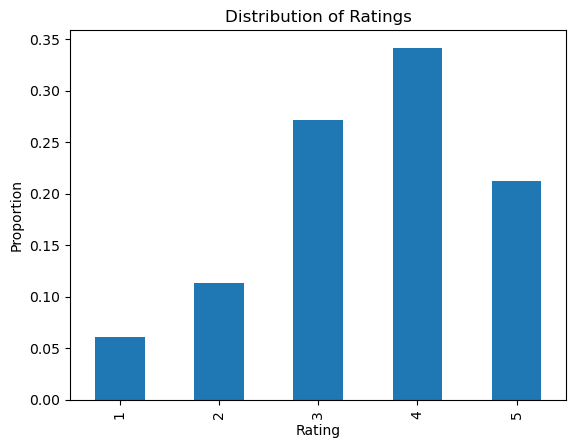

In [10]:
data_df.rating.value_counts(normalize=True).sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating"); plt.ylabel("Proportion")
plt.show()

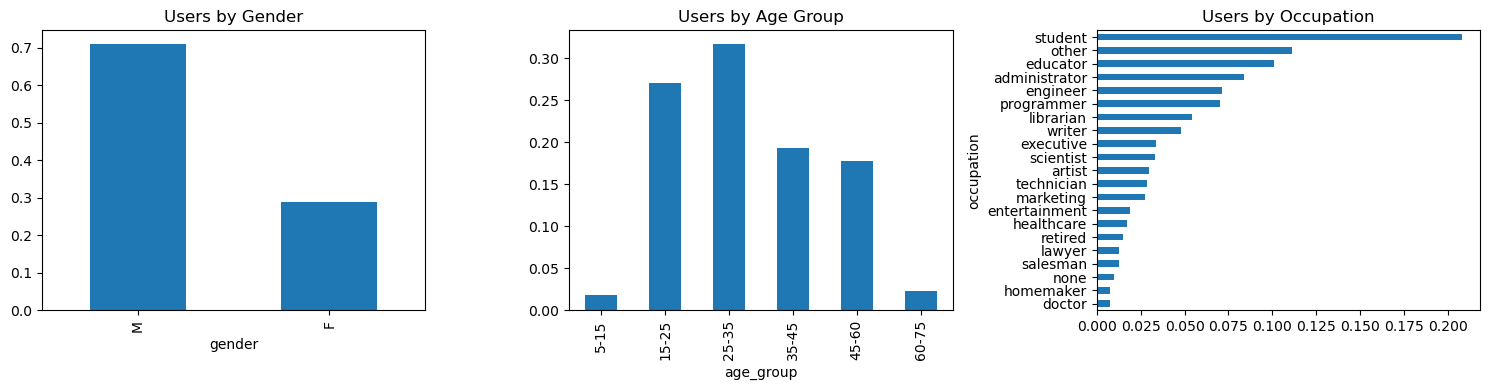

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
user_df.gender.value_counts(normalize=True).plot(kind="bar", ax=axes[0], title="Users by Gender")
user_df.age_group.value_counts(normalize=True).sort_index().plot(kind="bar", ax=axes[1], title="Users by Age Group")
user_df.occupation.value_counts(normalize=True).sort_values().plot(kind="barh", ax=axes[2], title="Users by Occupation")
plt.tight_layout()
plt.show()

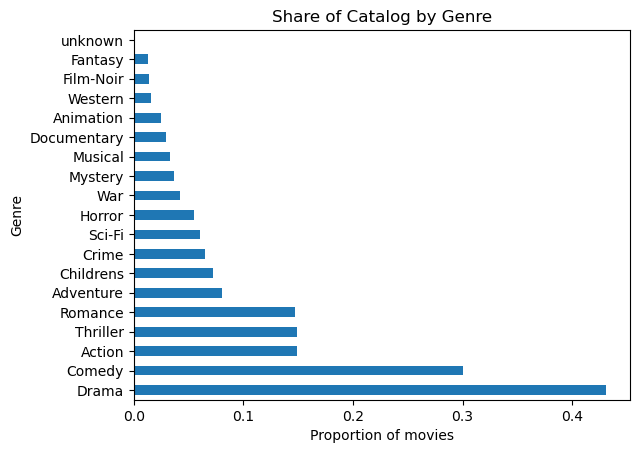

In [12]:
genre_column_names = item_df.loc[:, "unknown":"Western"].columns.to_list()
item_df[genre_column_names].mean().sort_values(ascending=False).plot(kind="barh")
plt.title("Share of Catalog by Genre")
plt.xlabel("Proportion of movies"); plt.ylabel("Genre")
plt.show()

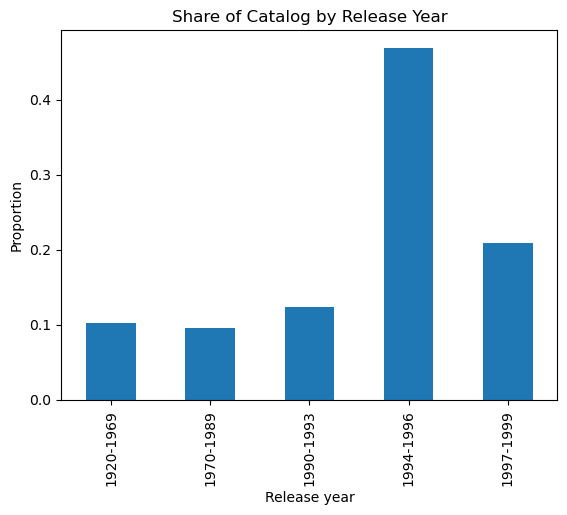

In [13]:
item_df.release_year.value_counts(normalize=True).sort_index().plot(kind="bar")
plt.title("Share of Catalog by Release Year")
plt.xlabel("Release year"); plt.ylabel("Proportion")
plt.show()

The dataset skews toward the mid-1990s: ~80% of films were released between
1990 and 1998, with 1994-1996 alone accounting for almost half the catalog.
Users skew male and are concentrated in the 25-35 age band. Ratings themselves
skew positive — most fall in the 3-5 star range — so any "low rating" finding
below should be read as *relatively* low, not as an unpopular movie in
absolute terms.

## Analysis

### Do user demographics affect ratings?

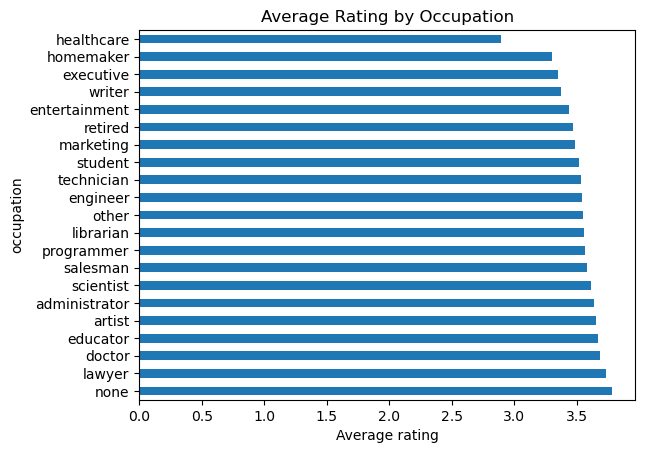

In [14]:
all_merged.groupby("occupation")["rating"].mean().sort_values(ascending=False).plot(kind="barh")
plt.title("Average Rating by Occupation")
plt.xlabel("Average rating")
plt.show()

People with occupation "other", lawyers, doctors, and educators rate films
highest on average. Executives, homemakers, and healthcare workers rate
lowest.

In [15]:
all_merged.groupby("gender")["rating"].mean().sort_values(ascending=False)

gender
F    3.531507
M    3.529289
Name: rating, dtype: float64

Women and men rate films almost identically (3.53 vs 3.53 on average), so gender has no practical effect on ratings.

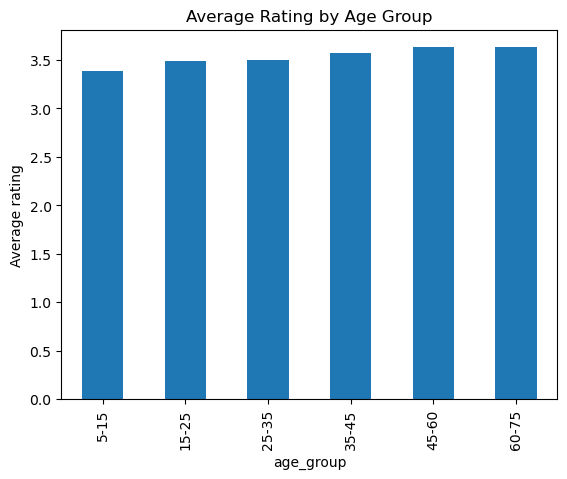

In [16]:
avg_rating_by_age = all_merged.groupby("age_group", observed=False)["rating"].mean().sort_index()
avg_rating_by_age.plot(kind="bar")
plt.title("Average Rating by Age Group")
plt.ylabel("Average rating")
plt.show()

In [17]:
age_groups = [g["rating"].values for _, g in all_merged.groupby("age_group", observed=True)]
f_stat, p_val = f_oneway(*age_groups)
print(f"Age group ANOVA: F={f_stat:.2f}, p={p_val:.4f}")

Age group ANOVA: F=51.86, p=0.0000


Older users rate films higher on average, and the difference is statistically
significant (ANOVA). With 100,000 ratings even small differences are significant, so the
size of the gap matters more than the p-value. The 5-15 age group rates lowest, but this
group is only ~1.8% of users, so that specific average should be treated with caution.

### Does release year affect ratings?

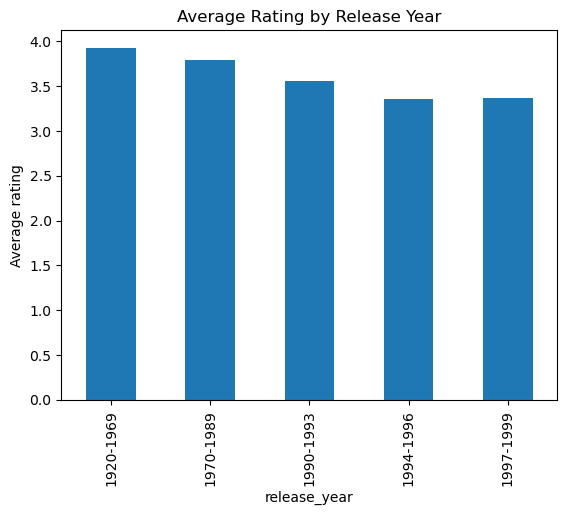

In [18]:
avg_rating_by_year = all_merged.groupby("release_year", observed=True)["rating"].mean().sort_index()
avg_rating_by_year.plot(kind="bar")
plt.title("Average Rating by Release Year")
plt.ylabel("Average rating")
plt.show()

In [19]:
year_groups = [g["rating"].values for _, g in all_merged.groupby("release_year", observed=True)]
f_stat, p_val = f_oneway(*year_groups)
print(f"Release year ANOVA: F={f_stat:.2f}, p={p_val:.4f}")

Release year ANOVA: F=948.12, p=0.0000


Films released earlier have higher average ratings than films released more
recently, and the difference is statistically significant. This is
plausible evidence of survivorship bias — see Limitations.

### Which movies are highest-rated, once popularity is accounted for?

Hypothesis: the number of ratings a movie has is a proxy for its popularity,
and popular movies may have different (likely higher) average ratings than
obscure ones. We test this before deciding on a minimum-ratings threshold for
a "top movies" ranking.

In [20]:
RATING_THRESHOLD = 80  # ~75th percentile of ratings-per-movie

movie_counts = all_merged.groupby("movie_id")["rating"].count()
popular_ids = movie_counts[movie_counts > RATING_THRESHOLD].index

print(f"Avg rating, movies with >{RATING_THRESHOLD} ratings:",
      all_merged.loc[all_merged.movie_id.isin(popular_ids), "rating"].mean())
print(f"Avg rating, movies with <={RATING_THRESHOLD} ratings:",
      all_merged.loc[~all_merged.movie_id.isin(popular_ids), "rating"].mean())

Avg rating, movies with >80 ratings: 3.6695048704692095
Avg rating, movies with <=80 ratings: 3.1750292128465705


Movies with more than 80 ratings do have a meaningfully higher average
rating, confirming the hypothesis. We use this threshold when ranking top
movies, so obscure titles with one or two high ratings don't outrank
consistently well-reviewed, widely-seen films.

In [21]:
top_10 = (all_merged[all_merged.movie_id.isin(popular_ids)]
          .groupby("movie_id")
          .agg(movie_title=("movie_title", "first"),
               avg_rating=("rating", "mean"),
               num_ratings=("rating", "count"),
               release_year=("release_year", "first"))
          .sort_values("avg_rating", ascending=False)
          .head(10))
top_10

,movie_title,avg_rating,num_ratings,release_year
movie_id,,,,
408,"Close Shave, A (1995)",4.491071,112,1994-1996
318,Schindler's List (1993),4.466443,298,1990-1993
169,"Wrong Trousers, The (1993)",4.466102,118,1990-1993
483,Casablanca (1942),4.456790,243,1920-1969
64,"Shawshank Redemption, The (1994)",4.445230,283,1994-1996
603,Rear Window (1954),4.387560,209,1920-1969
12,"Usual Suspects, The (1995)",4.385768,267,1994-1996
50,Star Wars (1977),4.358491,583,1970-1989
178,12 Angry Men (1957),4.344000,125,1920-1969


In [22]:
top_10.release_year.value_counts().sort_values(ascending=False)

release_year
1920-1969    4
1994-1996    3
1990-1993    2
1970-1989    1
1997-1999    0
Name: count, dtype: int64

4 of the top 10 films were released between 1920-1969 — disproportionate
given that bucket is a small share of the catalog. This lines up with the
release-year finding above, and with older users (who rate higher on average)
possibly favoring older films.

### Does genre affect ratings, and does that interact with demographics?

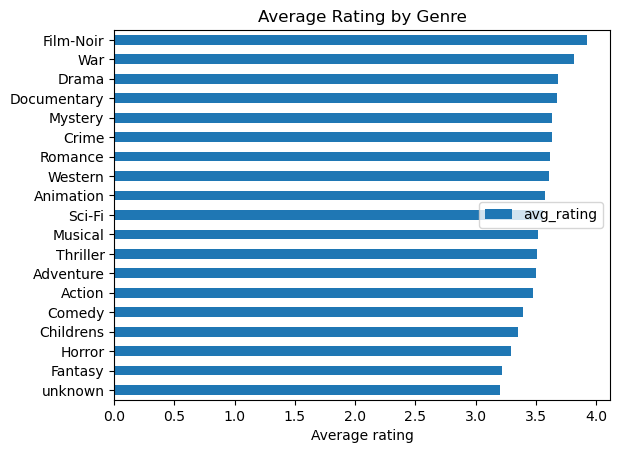

In [23]:
def calc_avg_rating_df(df):
    """Average rating per genre for a given subset of all_merged."""
    return {g: df.loc[df[g] == 1, "rating"].mean() for g in genre_column_names}

ratings_by_genre = (pd.DataFrame.from_dict(calc_avg_rating_df(all_merged), orient="index",
                                            columns=["avg_rating"])
                     .sort_values("avg_rating"))
ratings_by_genre.plot(kind="barh")
plt.title("Average Rating by Genre")
plt.xlabel("Average rating")
plt.show()

Film-Noir, War, Drama, and Documentary have the highest average ratings.
Children's, Horror, Fantasy, and films with no listed genre have the lowest.

**Caveat for the cuts below:** unlike the top-10 movie ranking, these
genre-by-demographic breakdowns do not enforce a minimum-ratings threshold.
Some "top genre for group X" results may be driven by very few ratings —
treat them as directional, not conclusive.

In [24]:
occupation_list = all_merged.occupation.unique()
by_occupation = pd.DataFrame(
    {occ: calc_avg_rating_df(all_merged[all_merged.occupation == occ]) for occ in occupation_list}
)
by_occupation.apply(lambda col: col.nlargest(5))

,writer,executive,technician,educator,engineer,librarian,programmer,administrator,student,retired,other,doctor,marketing,artist,lawyer,salesman,homemaker,healthcare,none,entertainment,scientist
Action,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.053726,NaN,NaN,NaN
Animation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.628571,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.976744,NaN,NaN
Crime,NaN,NaN,NaN,NaN,3.666121,NaN,NaN,NaN,3.657407,3.613139,NaN,3.804878,NaN,NaN,NaN,3.860759,NaN,NaN,NaN,3.710145,3.813559
Documentary,3.782609,NaN,3.958333,NaN,3.666667,3.812500,NaN,3.875000,3.829060,NaN,3.784615,NaN,3.583333,4.147059,3.900000,4.000000,3.500000,NaN,4.000000,3.869565,3.882353
Drama,3.511322,NaN,3.694981,3.811259,3.701554,3.701603,3.755714,3.796063,3.702842,NaN,3.719294,NaN,3.608010,NaN,NaN,3.984227,3.538462,NaN,3.932836,NaN,3.815451
Film-Noir,3.968000,3.603448,4.021739,4.064356,3.924138,3.968750,3.886525,3.972789,3.832714,4.023256,3.842466,4.111111,4.100000,4.234375,4.500000,NaN,NaN,3.100000,NaN,3.914894,4.025641
Horror,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.866667,NaN,NaN,NaN,NaN,NaN,NaN
Musical,NaN,3.625954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.277778,NaN,NaN,NaN
Mystery,3.629851,NaN,NaN,3.789474,NaN,3.689420,NaN,3.763636,NaN,3.714286,NaN,3.962963,3.585938,NaN,3.923077,NaN,3.687500,3.121429,NaN,NaN,NaN
Romance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.525424,NaN,NaN,NaN,NaN


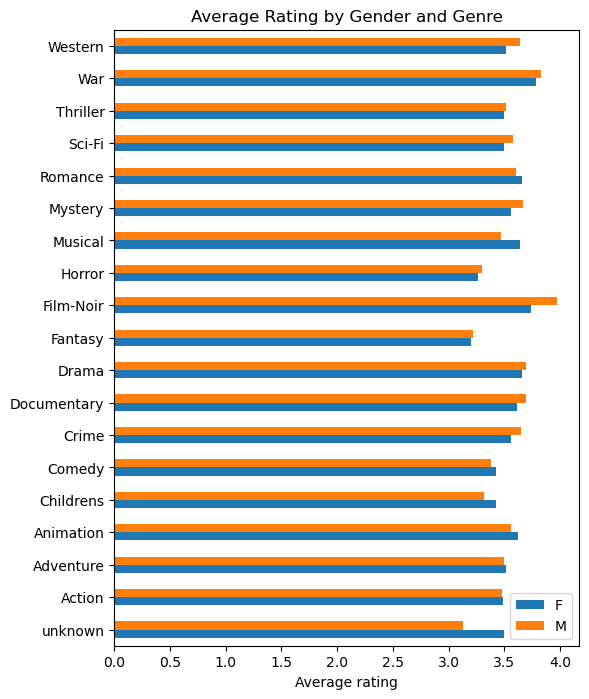

In [25]:
by_gender = pd.DataFrame(
    {g: calc_avg_rating_df(all_merged[all_merged.gender == g]) for g in ["F", "M"]}
)
by_gender.plot(kind="barh", figsize=(6, 8), title="Average Rating by Gender and Genre")
plt.xlabel("Average rating")
plt.show()

In [26]:
age_group_list = all_merged.age_group.cat.categories.to_list()
by_age_group = pd.DataFrame(
    {ag: calc_avg_rating_df(all_merged[all_merged.age_group == ag]) for ag in age_group_list}
)
by_age_group.apply(lambda col: col.nlargest(5))

,5-15,15-25,25-35,35-45,45-60,60-75
Animation,3.592105,NaN,3.605551,NaN,NaN,NaN
Crime,3.591398,NaN,NaN,NaN,NaN,NaN
Documentary,NaN,3.685567,3.679167,3.775362,NaN,NaN
Drama,NaN,3.662493,3.653238,NaN,3.751958,3.769352
Film-Noir,NaN,3.821809,3.869643,3.985915,4.046683,3.947368
Horror,3.586207,NaN,NaN,NaN,NaN,NaN
Mystery,NaN,NaN,NaN,3.728632,3.786042,3.788732
Sci-Fi,3.647436,NaN,NaN,NaN,NaN,NaN
War,3.717391,3.800842,3.760632,3.846591,3.917241,3.784173
Western,NaN,NaN,NaN,NaN,3.865497,3.937500


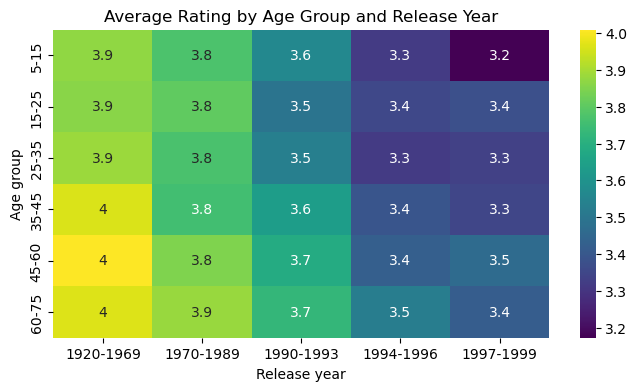

In [27]:
avg_rating_by_age_year = all_merged.groupby(["age_group", "release_year"], observed=True)["rating"].mean().unstack()
plt.figure(figsize=(8, 4))
sns.heatmap(avg_rating_by_age_year, annot=True, cmap="viridis")
plt.title("Average Rating by Age Group and Release Year")
plt.xlabel("Release year"); plt.ylabel("Age group")
plt.show()

Older movies receive higher average ratings than newer ones in every age group, so
the release-year effect isn't specific to older raters. The heatmap doesn't control for
how many ratings sit in each cell, so cells for the youngest and oldest age groups
should be read with caution.

## Engagement Patterns

Separately from rating *quality*, we look at rating *volume* — how many
reviews users in each segment tend to leave. On average, each user left
around 106 ratings.

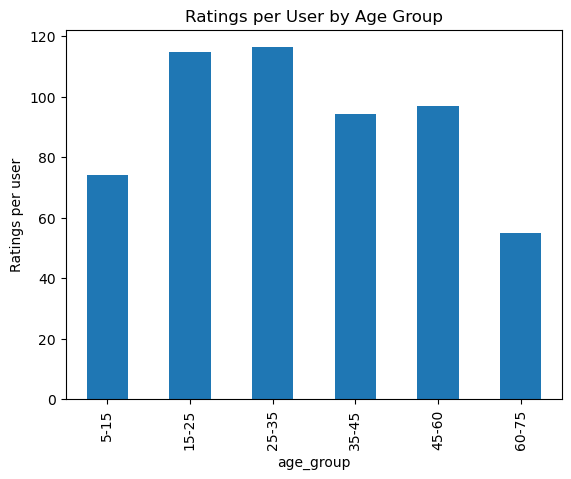

In [28]:
def per_capita(count_series, group_col):
    return count_series / all_merged.groupby(group_col, observed=False)["user_id"].nunique()

per_capita(all_merged.age_group.value_counts(), "age_group").sort_index().plot(kind="bar")
plt.title("Ratings per User by Age Group")
plt.ylabel("Ratings per user")
plt.show()

Users aged 15-35 are more active than average; those 35-60 are less active
than average.

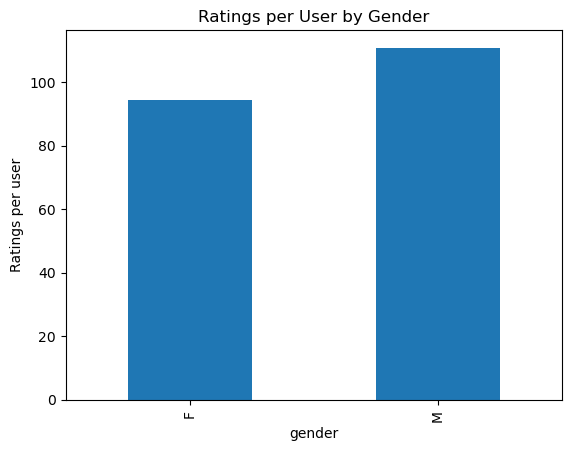

In [29]:
per_capita(all_merged.gender.value_counts(), "gender").plot(kind="bar")
plt.title("Ratings per User by Gender")
plt.ylabel("Ratings per user")
plt.show()

Women leave fewer ratings than average; men leave more.

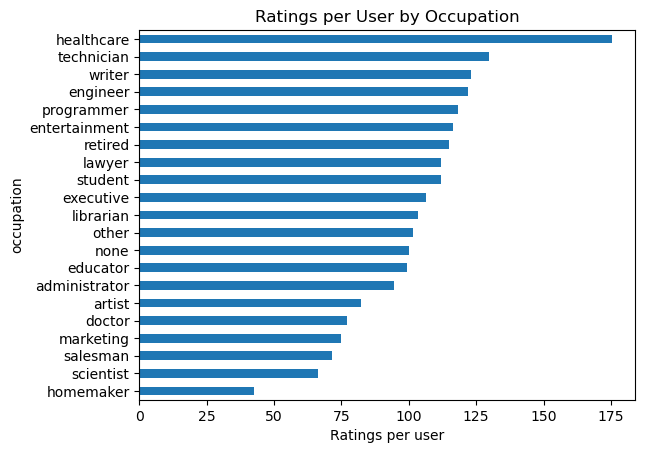

In [30]:
per_capita(all_merged.occupation.value_counts(), "occupation").sort_values().plot(kind="barh")
plt.title("Ratings per User by Occupation")
plt.xlabel("Ratings per user")
plt.show()

Ratings-per-user varies substantially by occupation — more than by age or gender.

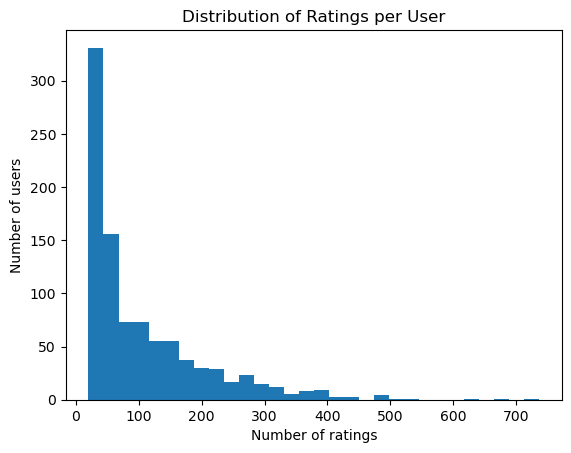

In [31]:
all_merged.groupby("user_id")["movie_id"].nunique().plot(kind="hist", bins=30)
plt.title("Distribution of Ratings per User")
plt.xlabel("Number of ratings")
plt.ylabel("Number of users")
plt.show()

The mean (106) hides a right-skewed distribution: most users rate far fewer
than 106 movies, while a small number of very active users rate many more,
pulling the average up.

## Key Findings & Recommendations

**1. Demographics correlate with rating behavior, but weakly.**
Occupation shows the clearest pattern — lawyers, doctors, and educators rate
highest on average, executives, homemakers, and healthcare workers rate
lowest. Gender differences are negligible. Age shows a mild upward trend,
though the youngest bracket (5-15, ~1.8% of users) is too small to trust on
its own. *Recommendation: don't build demographic-based rating adjustments on
gender or the youngest age bracket — sample sizes are too thin to be reliable.*

**2. Older movies rate higher, and this is likely survivorship bias, not
quality.**
Films from 1920-1969 have the highest average ratings of any release-year
bucket (statistically significant by ANOVA) and make up 4 of the top 10
movies among those with more than 80 ratings. This is a common pattern in ratings data:
poorly-received old films fall out of circulation and stop being rated, so
what remains is a filtered, better-than-average sample.
*Recommendation: don't treat release year as a causal driver of quality in
any downstream model without controlling for this.*

**3. Popularity and rating quality are correlated — set a minimum-ratings
threshold before ranking movies.**
Movies with more than 80 ratings have a meaningfully higher average rating
than movies with fewer. Ranking "best movies" without this threshold would
surface obscure titles with only a handful of high ratings.
*Recommendation: any "top movies" feature should enforce a minimum ratings
count, not just sort by average.*

**4. Genre preference varies by both quality perception and audience.**
Film-Noir, War, Drama, and Documentary have the highest average ratings;
Children's, Horror, and Fantasy the lowest. This holds directionally across
gender and occupation, though rankings shuffle somewhat by age group.
*Recommendation: genre-based content decisions should be paired with the
audience segment they're aimed at, rather than treated as one universal
ranking.*

**5. Engagement varies more by occupation than by age or gender.**
Users aged 15-35 rate more actively than average; 35-60 less so. Men leave
slightly more ratings per person than women. But the spread across occupation
groups is the largest of any segment studied. *Recommendation: if the goal is
increasing engagement, occupation-based segmentation looks more promising
than age- or gender-based campaigns.*

## Limitations & Next Steps

**Limitations:**
- 9 ratings (one film with no release date) were assigned the median release date. The
  effect is negligible, but it is an imputation.
- Bivariate cuts (genre × occupation, genre × age group) don't enforce the
  same minimum-ratings threshold used in the top-10 analysis — some
  "top genre for group X" results may be driven by very few ratings.
- The 5-15 age bracket and several occupation categories have small sample
  sizes; averages for these groups are noisy and shouldn't be over-interpreted.
- ANOVA confirms that group means differ, but doesn't establish *why* — e.g.
  the release-year effect is plausibly survivorship bias rather than a real
  quality signal, but that's an inference here, not something tested directly.
- All relationships examined are one or two factors at a time; effects
  haven't been isolated from each other (e.g. age and occupation are
  correlated, so an "occupation effect" may partly be an age effect in
  disguise).

**Next steps:**
- Fit a multivariate regression (`rating ~ age + gender + occupation + genre +
  release_year`) to isolate each factor's effect while controlling for the
  others.
- Test the survivorship-bias hypothesis directly: check whether older movies
  with *few* ratings also show inflated averages, or whether the effect only
  holds for movies that cleared the popularity threshold.
- Extend the engagement analysis into a retention angle using timestamps,
  e.g. whether per-capita rating rates are stable over time or declining for
  particular segments.